<a href="https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_4_1_4_2_Graph_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_4_1_4_2_Graph_Modeling.ipynb)

# MAT 422 - Sections 4.1 and 4.2: Graphs and Graph Modeling

**Topics:** Graph basics and adjacency representations, Degree and neighbors, Graph traversal, Graph and graph modeling

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=3, suppress=True)


## Graph basics and adjacency representations

A graph is a set of nodes (dots) joined by edges (lines). The adjacency matrix is a table with a 1 in row *i*, column *j* when nodes *i* and *j* are connected, and a 0 otherwise. Adding up a row counts that node's connections, which is its degree.


In [7]:
nodes = ["A", "B", "C", "D", "E"]
edges = [("A","B"), ("A","C"), ("B","D"), ("C","D"), ("D","E")]
index = {node: i for i, node in enumerate(nodes)}
adj = np.zeros((len(nodes), len(nodes)), dtype=int)
for u, v in edges:
    adj[index[u], index[v]] = 1
    adj[index[v], index[u]] = 1

print("Adjacency matrix:")
print(adj)
print("Degrees:", dict(zip(nodes, adj.sum(axis=1))))


Adjacency matrix:
[[0 1 1 0 0]
 [1 0 0 1 0]
 [1 0 0 1 0]
 [0 1 1 0 1]
 [0 0 0 1 0]]
Degrees: {'A': np.int64(2), 'B': np.int64(2), 'C': np.int64(2), 'D': np.int64(3), 'E': np.int64(1)}


Each shaded square below is one connection. The picture is a mirror image across the diagonal because our edges have no direction: if A is connected to B, then B is connected to A. The printed check confirms the symmetry with numbers.

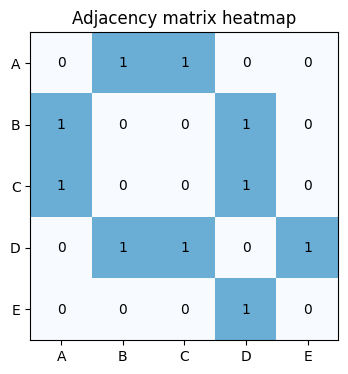

Symmetric: True


In [8]:
plt.figure(figsize=(4, 4))
plt.imshow(adj, cmap="Blues", vmin=0, vmax=2)
plt.xticks(range(len(nodes)), nodes)
plt.yticks(range(len(nodes)), nodes)
for i in range(len(nodes)):
    for j in range(len(nodes)):
        plt.text(j, i, adj[i, j], ha="center", va="center")
plt.title("Adjacency matrix heatmap")
plt.show()

print("Symmetric:", np.array_equal(adj, adj.T))


## Degree and neighbors

The neighbors of a node are the nodes it touches directly, and its degree is how many neighbors it has. The adjacency list below stores each node's neighbors. The cell also defines breadth-first search (BFS), which visits the start node, then its neighbors, then their neighbors.


In [9]:
adj_list = {node: [] for node in nodes}
for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

def bfs(start):
    seen = {start}
    order = []
    queue = deque([start])
    while queue:
        node = queue.popleft()
        order.append(node)
        for neighbor in adj_list[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                queue.append(neighbor)
    return order

print("Adjacency list:", adj_list)
print("BFS order from A:", bfs("A"))


Adjacency list: {'A': ['B', 'C'], 'B': ['A', 'D'], 'C': ['A', 'D'], 'D': ['B', 'C', 'E'], 'E': ['D']}
BFS order from A: ['A', 'B', 'C', 'D', 'E']


In the figure below, each bar is the number of neighbors of one node. D is the best-connected node (degree 3) and E has only one neighbor. The printed check shows that the degrees add up to twice the number of edges, because every edge is counted once at each of its two ends.


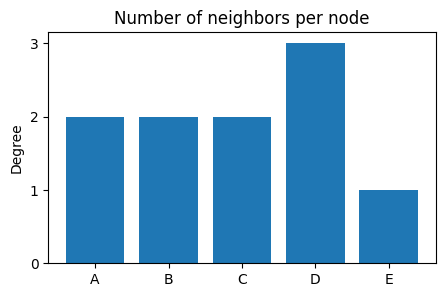

Sum of degrees: 10 | 2 x number of edges: 10


In [10]:
degrees = [len(adj_list[node]) for node in nodes]

plt.figure(figsize=(5, 3))
plt.bar(nodes, degrees, color="tab:blue")
plt.yticks(range(max(degrees) + 1))
plt.ylabel("Degree")
plt.title("Number of neighbors per node")
plt.show()

print("Sum of degrees:", sum(degrees), "| 2 x number of edges:", 2 * len(edges))


## Graph traversal

Traversal means visiting every node by walking along edges. BFS spreads out from the start like ripples in water, so closer nodes are visited first. The drawing below lets you follow the BFS order A, B, C, D, E by eye.



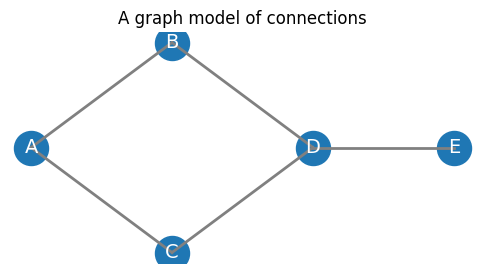

In [11]:
positions = {
    "A": (0, 1),
    "B": (1, 2),
    "C": (1, 0),
    "D": (2, 1),
    "E": (3, 1),
}

plt.figure(figsize=(6, 3))
for u, v in edges:
    x = [positions[u][0], positions[v][0]]
    y = [positions[u][1], positions[v][1]]
    plt.plot(x, y, color="gray", linewidth=2)
for node, (x, y) in positions.items():
    plt.scatter(x, y, s=600, color="tab:blue")
    plt.text(x, y, node, color="white", ha="center", va="center", fontsize=14)
plt.axis("off")
plt.title("A graph model of connections")
plt.show()


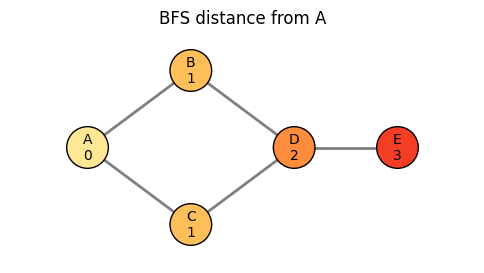

Distances from A: {'A': 0, 'B': 1, 'C': 1, 'D': 2, 'E': 3}


In [12]:
dist = {"A": 0}
queue = deque(["A"])
while queue:
    node = queue.popleft()
    for neighbor in adj_list[node]:
        if neighbor not in dist:
            dist[neighbor] = dist[node] + 1
            queue.append(neighbor)

plt.figure(figsize=(6, 3))
for u, v in edges:
    x = [positions[u][0], positions[v][0]]
    y = [positions[u][1], positions[v][1]]
    plt.plot(x, y, color="gray", linewidth=2, zorder=1)
xs = [positions[node][0] for node in nodes]
ys = [positions[node][1] for node in nodes]
plt.scatter(xs, ys, s=900, c=[dist[node] for node in nodes], cmap="YlOrRd", vmin=-1, vmax=5, edgecolors="black", zorder=2)
for node in nodes:
    plt.text(*positions[node], f"{node}\n{dist[node]}", ha="center", va="center", zorder=3)
plt.margins(0.25)
plt.axis("off")
plt.title("BFS distance from A")
plt.show()

print("Distances from A:", dist)


The number under each letter is how many edges that node is from A. Darker nodes are farther away, so BFS reaches them later. B and C are one step away, D is two, and E is three.


## Graph and graph modeling

Graph modeling means letting nodes and edges stand for something real. Here nodes are people and edges are contacts between them. Person A is infected, and each person's risk score is the fraction of their contacts who are infected.

In [13]:
# Example interpretation: a simple contact network.
infection_state = {"A": "infected", "B": "susceptible", "C": "susceptible", "D": "susceptible", "E": "susceptible"}
risk_scores = {}
for node in nodes:
    infected_neighbors = sum(infection_state[n] == "infected" for n in adj_list[node])
    risk_scores[node] = infected_neighbors / max(1, len(adj_list[node]))

print("Risk score from infected neighbors:")
print(risk_scores)


Risk score from infected neighbors:
{'A': 0.0, 'B': 0.5, 'C': 0.5, 'D': 0.0, 'E': 0.0}


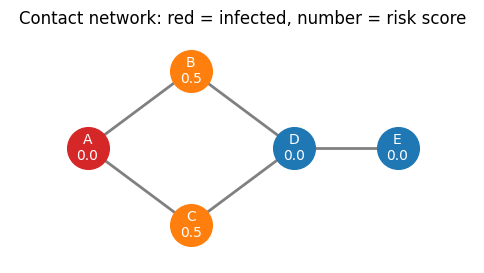

In [14]:
plt.figure(figsize=(6, 3))
for u, v in edges:
    x = [positions[u][0], positions[v][0]]
    y = [positions[u][1], positions[v][1]]
    plt.plot(x, y, color="gray", linewidth=2, zorder=1)
for node, (x, y) in positions.items():
    if infection_state[node] == "infected":
        color = "tab:red"
    elif risk_scores[node] > 0:
        color = "tab:orange"
    else:
        color = "tab:blue"
    plt.scatter(x, y, s=900, color=color, zorder=2)
    plt.text(x, y, f"{node}\n{risk_scores[node]:.1f}", color="white", ha="center", va="center", zorder=3)
plt.margins(0.25)
plt.axis("off")
plt.title("Contact network: red = infected, number = risk score")
plt.show()


Red is the infected person, orange marks people with an infected contact, and blue marks people with none. B and C touch A directly, so each has risk 0.5 (1 of their 2 contacts). D and E have no infected contacts yet, so their risk is 0.


## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
